# Price what you would relax: feasibility relaxation and priced slacks
[![priced_relaxation.ipynb](https://img.shields.io/badge/github-%23121011.svg?logo=github)](https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Open In Deepnote](https://deepnote.com/buttons/launch-in-deepnote-small.svg)](https://deepnote.com/launch?url=https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Open In Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Open In Gradient](https://assets.paperspace.io/img/gradient-badge.svg)](https://console.paperspace.com/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Open In SageMaker Studio Lab](https://studiolab.sagemaker.aws/studiolab.svg)](https://studiolab.sagemaker.aws/import/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb) [![Powered by AMPL](https://h.ampl.com/https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/priced_relaxation.ipynb)](https://ampl.com)

Description: After an infeasible unit commitment: a priced feasibility relaxation through AMPL suffixes (.rhspen, .lbpen, .ubpen) against a slack priced in the model, which runs on any solver and sweeps into an operating reserve demand curve

Tags: mp, feasibility-relaxation, infeasibility, suffixes, unit-commitment, energy, milp, amplpy, highs, gurobi

<!--
Domain: Energy
Subdomain: Unit Commitment
Model type: MILP
Level: Lecture
Algorithm: Debugging Infeasibility
Subject: Feasibility Relaxation
-->

Notebook author: Gleb Belov <<gleb@ampl.com>>

References:
1. MP solver features, feasibility relaxation: https://mp.ampl.com/features-guide.html
2. Chinneck, J.W. (2008). *Feasibility and Infeasibility in Optimization: Algorithms and Computational Methods*. Springer.
3. Hogan, W.W. (2013). Electricity scarcity pricing through operating reserves. *Economics of Energy & Environmental Policy* 2(2), 65-86.

In [1]:
# Install dependencies
%pip install -q amplpy pandas matplotlib

In [2]:
# Google Colab & Kaggle integration
from amplpy import AMPL, ampl_notebook

ampl = ampl_notebook(
    modules=["highs", "gurobi"],  # modules to install
    license_uuid="default",  # license to use
)  # instantiate AMPL object and register magics

## The point

An IIS says **where** a model is infeasible. The next question is **how much** would have to give, and **what it
would cost**. Two ways to answer it:

* a **feasibility relaxation**: let chosen constraints be violated at a price per unit, and ask the solver for the
  cheapest violation (`alg:feasrelax`, with the prices in suffixes);
* **pricing the violation in the model**: give the rule a slack variable with a price in the objective. This runs on
  any solver, and the price becomes a decision lever.

This notebook does both on the unit commitment model of this series, after the outage that made it infeasible in the
IIS notebook: the largest unit out and 15 % spinning reserve.

In [3]:
SOLVER = "highs"  # the priced model: any MP-based MILP solver
SOLVER_RELAX = (
    "gurobi"  # a feasibility relaxation: gurobi, cplex, copt (HiGHS has none)
)

## The model and the outage

In [4]:
MODEL = r"""
set UNITS;
param T integer > 0;
set HOURS := 1..T;
param dt > 0;                          # hours per period
param demand {HOURS} >= 0;             # MW
param reserve {HOURS} >= 0;            # spinning reserve required, MW
param min_online integer >= 0;         # units online, for system inertia
param pmin {UNITS} >= 0;
param pmax {g in UNITS} >= pmin[g];
param ramp {UNITS} > 0;                # MW per period
param minup {UNITS} integer >= 1;
param mindn {UNITS} integer >= 1;
param fuel {UNITS} >= 0;               # $/MWh
param noload {UNITS} >= 0;             # $/h while on
param startcost {UNITS} >= 0;          # $ per start
param emis {UNITS} >= 0;               # t CO2 per MWh
param on0 {UNITS} binary;              # on before the horizon
param p0 {UNITS} >= 0;                 # output before the horizon

var On {UNITS, HOURS} binary;
var Start {UNITS, HOURS} >= 0, <= 1;
var Stop {UNITS, HOURS} >= 0, <= 1;
var P {g in UNITS, HOURS} >= 0, <= pmax[g];

var Cost = sum {g in UNITS, t in HOURS}
             (dt * (fuel[g] * P[g,t] + noload[g] * On[g,t]) + startcost[g] * Start[g,t]);
minimize Total_Cost: Cost;

subject to Output_Lo {g in UNITS, t in HOURS}: P[g,t] >= pmin[g] * On[g,t];
subject to Output_Up {g in UNITS, t in HOURS}: P[g,t] <= pmax[g] * On[g,t];
subject to Balance {t in HOURS}: sum {g in UNITS} P[g,t] = demand[t];
subject to Spinning_Reserve {t in HOURS}:
   sum {g in UNITS} (pmax[g] * On[g,t] - P[g,t]) >= reserve[t];
subject to Inertia {t in HOURS}: sum {g in UNITS} On[g,t] >= min_online;
subject to Switch {g in UNITS, t in HOURS}:
   Start[g,t] - Stop[g,t] = On[g,t] - (if t = 1 then on0[g] else On[g,t-1]);
subject to Ramp_Up {g in UNITS, t in HOURS}:
   P[g,t] - (if t = 1 then p0[g] else P[g,t-1]) <= ramp[g] + pmax[g] * Start[g,t];
subject to Ramp_Down {g in UNITS, t in HOURS}:
   (if t = 1 then p0[g] else P[g,t-1]) - P[g,t] <= ramp[g] + pmax[g] * Stop[g,t];
subject to Min_Up {g in UNITS, t in HOURS}:
   sum {s in max(1, t - minup[g] + 1) .. t} Start[g,s] <= On[g,t];
subject to Min_Down {g in UNITS, t in HOURS}:
   sum {s in max(1, t - mindn[g] + 1) .. t} Stop[g,s] <= 1 - On[g,t];
"""

In [5]:
import pandas as pd

# A small thermal fleet: seven units of four types, twelve 2-hour periods
units = pd.DataFrame(
    {
        "pmin": [300, 120, 80, 20, 300, 120, 80],  # MW
        "pmax": [500, 350, 250, 100, 500, 350, 250],  # MW
        "ramp": [60, 80, 120, 100, 60, 80, 120],  # MW per period
        "minup": [12, 6, 2, 1, 12, 6, 2],  # periods
        "mindn": [12, 5, 2, 1, 12, 5, 2],  # periods
        "fuel": [9, 24, 38, 75, 9, 25, 39],  # $/MWh
        "noload": [800, 500, 300, 100, 800, 500, 300],  # $/h while on
        "startcost": [9000, 6000, 2000, 400, 9000, 6000, 2000],  # $ per start
        "emis": [0, 0.95, 0.37, 0.55, 0, 0.969, 0.3774],  # t CO2 per MWh
        "on0": [1, 1, 0, 0, 1, 1, 0],  # on before the horizon
        "p0": [400, 200, 0, 0, 400, 200, 0],  # MW before the horizon
    },
    index=["NUKE1", "COAL1", "CCGT1", "GT1", "NUKE2", "COAL2", "CCGT2"],
)
demand = [1027, 960, 1093, 1325, 1557, 1490, 1027, 960, 1557, 1656, 1457, 1093]  # MW


def load(units, reserve_frac, demand=demand, model=MODEL):
    """Reset the AMPL session, read the model and feed the data."""
    ampl.reset()
    ampl.eval(model)
    ampl.set_data(units, "UNITS")
    ampl.param["T"] = len(demand)
    ampl.param["dt"] = 2
    ampl.param["min_online"] = 2
    ampl.param["demand"] = {t + 1: d for t, d in enumerate(demand)}
    ampl.param["reserve"] = {
        t + 1: round(reserve_frac * d) for t, d in enumerate(demand)
    }


units

,pmin,pmax,ramp,minup,mindn,fuel,noload,startcost,emis,on0,p0
NUKE1,300,500,60,12,12,9,800,9000,0.0000,1,400
COAL1,120,350,80,6,5,24,500,6000,0.9500,1,200
CCGT1,80,250,120,2,2,38,300,2000,0.3700,0,0
GT1,20,100,100,1,1,75,100,400,0.5500,0,0
NUKE2,300,500,60,12,12,9,800,9000,0.0000,1,400
COAL2,120,350,80,6,5,25,500,6000,0.9690,1,200
CCGT2,80,250,120,2,2,39,300,2000,0.3774,0,0


In [6]:
outage = units.drop("NUKE1")
load(outage, reserve_frac=0.15)
ampl.solve(solver=SOLVER, verbose=False)
print(ampl.solve_result)

infeasible


## Suffixes for a feasibility relaxation

The prices are **IN suffixes**, declared in the model and set before the solve:

| suffix | on | meaning |
|---|---|---|
| `.rhspen` | constraints | price per unit of violation of the constraint |
| `.lbpen`, `.ubpen` | variables | price per unit of violation of the lower or upper bound |

A negative price means *may not be relaxed*. Here demand, reserve and inertia may give way, at very different
prices; every other row and every bound must hold. After the solve, a violated row shows a negative `.slack`.

In [7]:
PRICES = {
    "Balance": 5000,
    "Spinning_Reserve": 300,
    "Inertia": 1000,
}  # $ per unit of violation


def relax(mode, prices=PRICES, solver=SOLVER_RELAX):
    load(outage, reserve_frac=0.15)
    ampl.eval("suffix rhspen IN; suffix lbpen IN; suffix ubpen IN;")
    for name, con in ampl.get_constraints():
        price = prices.get(name, -1)  # -1: inviolable
        if con.is_scalar():
            con.set_suffix("rhspen", price)
        else:
            keys = [k for k, _ in con.instances()]
            con.set_suffix("rhspen", pd.Series(price, index=keys))
    # bounds stay as declared: alg:lbpen=-1 alg:ubpen=-1
    ampl.solve(
        solver=solver,
        **{f"{solver}_options": f"alg:feasrelax={mode} alg:lbpen=-1 alg:ubpen=-1"},
        verbose=False,
    )
    violations = {}
    for name in prices:
        slack = ampl.get_constraint(name).get_values(["slack"]).to_pandas().iloc[:, 0]
        short = -slack[slack < -1e-6]  # a negative slack is the violation
        if len(short):
            violations[name] = short.round(1).to_dict()
    return ampl.solve_result, round(ampl.get_value("Cost")), violations


for mode in (1, 4):
    print(f"alg:feasrelax={mode}:", relax(mode))

alg:feasrelax=1: ('solved', 823384, {'Spinning_Reserve': {10: 104}})
alg:feasrelax=4: ('solved', 687748, {'Spinning_Reserve': {10: 104.0}})


Both modes find the same diagnosis: **104 MW of spinning reserve missing in period 10**, the cheapest violation at
these prices (reserve is the cheapest rule to bend). They differ in what happens next:

* modes 1-3 minimise only the priced violation (sum, sum of squares, count); the plan around it is any plan with
  that violation, and its cost is incidental;
* modes 4-6 then minimise the original objective subject to that minimum violation: the cheapest plan that carries
  the smallest priced shortfall.

With the largest unit out, no price buys the reserve back: 104 MW is what is physically missing in period 10. The
relaxation is a measurement of the gap, not a plan to adopt as is.

## Pricing the violation in the model

The same question as a model: a slack `Short[t]` in the reserve row, with a price in the objective. The price is
now a parameter you can sweep, and the model runs on any MILP solver.

In [8]:
PRICED = MODEL.replace(
    "minimize Total_Cost: Cost;",
    """param reserve_price >= 0;               # $ per MW short, per period
var Short {HOURS} >= 0;                 # reserve not carried, MW
minimize Total_Cost: Cost + sum {t in HOURS} reserve_price * Short[t];""",
).replace(
    "   sum {g in UNITS} (pmax[g] * On[g,t] - P[g,t]) >= reserve[t];",
    "   sum {g in UNITS} (pmax[g] * On[g,t] - P[g,t]) + Short[t] >= reserve[t];",
)


def priced(fleet, reserve_frac, price):
    load(fleet, reserve_frac=reserve_frac, model=PRICED)
    ampl.param["reserve_price"] = price
    ampl.solve(solver=SOLVER, verbose=False)
    short = ampl.get_variable("Short").get_values().to_dict()
    return dict(
        price=price,
        cost=round(ampl.get_value("Cost")),
        short_MW=round(sum(short.values()), 1),
        periods={t: round(v) for t, v in short.items() if v > 1e-6},
    )


outage_curve = pd.DataFrame([priced(outage, 0.15, p) for p in (10, 30, 100, 300, 1000)])
outage_curve

,price,cost,short_MW,periods
0,10,673760,588,"{3: 57, 4: 74, 5: 91, 6: 14, 9: 91, 10: 204, 1..."
1,30,681168,232,"{3: 57, 6: 14, 10: 104, 12: 57}"
2,100,686068,118,"{6: 14, 10: 104}"
3,300,687748,104,{10: 104}
4,1000,687748,104,{10: 104}


At a low price the plan goes short wherever reserve costs more than its price (starts and no-load of extra units).
From 300 $/MW on, it carries everything it can, and the result is **the plan the relaxation returned in mode 4**:
the same cost and the same 104 MW short in period 10. The priced model on an open-source solver reproduces the
relaxation, and shows the whole trade-off around it.

## When the reserve can be bought

With the whole fleet available and a demanding reserve rule (30 % of demand), the model is feasible but costly. The
price now decides how much reserve to carry: this is an **operating reserve demand curve**, the operator states what
reserve is worth and the solver carries it where it is cheaper than that (Hogan, 2013).

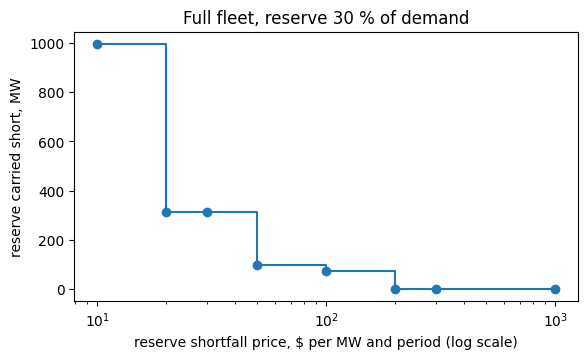

,price,cost,short_MW
0,10,483106,997.0
1,20,495974,313.0
2,30,495974,313.0
3,50,504574,97.0
4,100,506638,74.0
5,200,521434,0.0
6,300,521434,0.0
7,1000,521434,0.0


In [9]:
full_curve = pd.DataFrame(
    [priced(units, 0.30, p) for p in (10, 20, 30, 50, 100, 200, 300, 1000)]
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.step(full_curve.price, full_curve.short_MW, where="post", marker="o")
ax.set_xscale("log")
ax.set_xlabel("reserve shortfall price, $ per MW and period (log scale)")
ax.set_ylabel("reserve carried short, MW")
ax.set_title("Full fleet, reserve 30 % of demand")
plt.show()
full_curve[["price", "cost", "short_MW"]]

Between the two ends, each price gives one plan: how much reserve is worth carrying, and what it costs.

## Takeaways

* `alg:feasrelax` relaxes the rules you price with the IN suffixes `.rhspen` (constraints), `.lbpen` and `.ubpen`
  (bounds); a negative price keeps a rule hard. Read the violations from negative `.slack` values.
* Modes 1-3 measure the minimum priced violation; modes 4-6 also return the cheapest plan with it.
* A relaxation of a model that cannot be repaired is a diagnosis: it says how much is missing and where.
* Pricing a slack in the model gives the same answer at a high enough price, runs on any solver, and turns the price
  into a lever: sweep it to see the whole trade-off.